# 中间件：在 Agent 的关键步骤加入控制逻辑


## Agent 会调用工具之后，还缺什么？

第 07 章已经把“模型判断 → 工具执行 → 模型继续判断”交给 `create_agent`。实际应用还经常需要限制调用次数、压缩长对话、在工具执行前审核，以及在请求失败时重试。

这些逻辑影响运行过程，却不必反复写进每个天气查询或客户分析工具。**Middleware（中间件）通过 Agent 暴露的钩子，在特定步骤插入、修改或控制执行逻辑。**

~~~text
业务工具：查什么数据、执行什么操作
中间件：什么时候允许执行、使用什么模型、怎样处理历史与失败
~~~

本篇根据尚硅谷第 08 章《中间件》的 115 页课件整理，沿用前面的分节排版。内容分为内置中间件、组合顺序和自定义钩子；重复的调用日志保留关键含义，不逐页复制。

所有单元格均为 Markdown。示例代码只供阅读，不运行 Agent，不启动假服务，不发送邮件，也不执行文件修改或课程测试。


## 钩子：框架在指定时机调用你的逻辑

可以把 Agent 主流程看作一条流水线：某些工序前后留有插槽，你把检查、日志或处理函数挂上去，运行到相应位置时由框架调用。

中间件的收益主要有三点：同一规则可以复用到多个 Agent；业务工具保持职责清楚；控制逻辑可以挂在正确的执行阶段。

| 需求 | 合适的位置或方式 |
| --- | --- |
| 观察一次模型调用的前后状态 | before_model / after_model |
| 给当前请求选择模型或工具 | wrap_model_call |
| 处理某次工具执行的异常 | wrap_tool_call 或工具重试中间件 |
| 长对话摘要 | 模型调用前处理历史 |
| 工具执行前人工审核 | 模型提出工具请求后、工具执行前中断 |

钩子不是需要你在业务代码里逐个手动调用的普通辅助函数；它必须注册到 Agent，才能参与相应的生命周期。

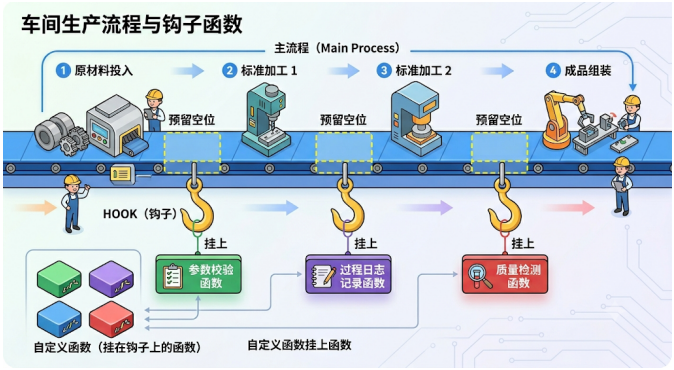

课件第 81 页：用流水线的预留位置解释 hook。


## 本章公共配置与两个模拟工具

继续采用前面 OpenAI 兼容服务的配置方式。模型和服务需要支持示例所用的工具调用能力；不把课件中的具体模型名当成所有账户都能使用的默认值。

~~~bash
uv add langchain langchain-openai python-dotenv
~~~

~~~dotenv
CLOSEAI_API_KEY=你的模型服务密钥
CLOSEAI_BASE_URL=服务商提供的OpenAI兼容API地址
CHAT_MODEL=账户可用且支持工具调用的模型名
~~~

~~~python
import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langchain.tools import tool

load_dotenv()
model = init_chat_model(
    model=os.environ["CHAT_MODEL"],
    model_provider="openai",
    api_key=os.environ["CLOSEAI_API_KEY"],
    base_url=os.environ["CLOSEAI_BASE_URL"],
    temperature=0,
)

@tool
def get_weather(city: str, include_forecast: bool = False) -> dict:
    """查询北京或上海的模拟天气；include_forecast 控制是否包含模拟明日预报。"""
    city = city.strip()
    data = {"北京": "多云，15～22℃", "上海": "晴，18～25℃"}
    return {
        "found": city in data,
        "city": city,
        "today": data.get(city),
        "tomorrow": "模拟预报：小雨" if city in data and include_forecast else None,
        "source": "固定模拟数据",
    }

@tool
def get_news() -> dict:
    """返回本地模拟新闻条目，不联网、不提供今日真实新闻。"""
    return {"items": ["模拟条目：AI 课程开始报名"], "source": "固定模拟数据"}
~~~

用模拟数据观察框架行为即可。示例回答必须说明来源，不能把固定字典包装成实时查询。


## 中间件怎样注册？

~~~python
from langchain.agents import create_agent
from langchain.agents.middleware import ModelCallLimitMiddleware

limited_agent = create_agent(
    model=model,
    middleware=[ModelCallLimitMiddleware(run_limit=5)],
)
~~~

`middleware` 接收中间件实例列表。内置中间件通常先实例化，再放入列表；装饰器定义的钩子已经被转换成中间件实例，后面直接传入名称即可。

工具、系统提示和中间件可以一起配置。中间件列表不是“先完整执行第一个，再完整执行第二个”：框架按各自实现的钩子组织运行，before、after 和 wrap 的顺序规则也不同。

上面的 `model` 使用上一节公共配置。后面的短示例同样沿用它，除非特别声明为独立示例。


## 内置中间件：按问题选择，不按数量堆叠

| 目标 | 本章涉及的中间件 |
| --- | --- |
| 长会话与上下文管理 | SummarizationMiddleware、ContextEditingMiddleware |
| 人工审核与信息处理 | HumanInTheLoopMiddleware、PIIMiddleware |
| 规划与进度 | TodoListMiddleware |
| 限制资源消耗 | ModelCallLimitMiddleware、ToolCallLimitMiddleware |
| 故障处理 | ToolRetryMiddleware、ModelRetryMiddleware、ModelFallbackMiddleware |
| 从大量工具中筛选 | LLMToolSelectorMiddleware |
| 模拟工具结果 | LLMToolEmulator |
| 搜索文件 | FilesystemFileSearchMiddleware |

这是一张功能索引，不是互斥分类。同一个中间件可以同时影响成本、可靠性和执行控制。

课件还介绍了 Shell、Filesystem 和 Subagent 的方向，其中 Filesystem / Subagent 来自 `deepagents`。中间件数量、所属包和支持范围随版本变化，不应记成“所有 LangChain 1.x 都固定只有 16 个”。


## 摘要：保留近期原文，把较早历史压成摘要

`SummarizationMiddleware` 在模型调用前检查历史长度，满足条件时用摘要模型压缩较早消息，并保留近期原始消息。

~~~text
旧消息 1 … 旧消息 n | 最近消息
       ↓ 摘要模型       ↓ 原样保留
        历史摘要     | 最近消息
                       ↓
                   业务模型继续回答
~~~

摘要模型与业务模型可以相同，也可以分别配置。摘要过程本身会调用模型、消耗时间和 token；它是用一次压缩调用换取后续较短上下文，不保证每个短会话都更省钱。

常见实现把摘要作为标记来源的 HumanMessage 放入消息状态，并重建历史。因此它不只是临时删减这一次请求；使用 checkpointer 时，压缩后的状态也会影响后续对话。

摘要有损。金额、引用、精确代码等不能仅靠自然语言摘要保存；必要原文应放在外部数据或有结构的状态中。


## SummarizationMiddleware 的参数

| 参数 | 含义 | 注意 |
| --- | --- | --- |
| `model` | 用于生成摘要的模型 | 对象能保留自定义服务地址 |
| `trigger` | 何时触发摘要 | 可用单个条件元组或多个条件的列表 |
| `keep` | 保留多少近期原始消息 | 一次指定一种度量 |
| `token_counter` | token 数估算或统计方法 | 默认近似计数不是供应商的精确计费数 |
| `summary_prompt` | 摘要提示模板 | 包含 `{messages}` 占位符 |
| `trim_tokens_to_summarize` | 送给摘要模型的历史 token 上限 | 过小会让部分历史在摘要前已被裁剪 |

常见条件写法：`("tokens", 4000)`、`("messages", 10)`、`("fraction", 0.8)`。

课件列出的多个元组条件按“任一满足”触发。`keep=("messages", 2)` 表示保留近期消息数量，不是保留两轮对话；存在工具调用时还需要维护请求与结果的有效配对，实际边界可能调整。

参数名是 **`trim_tokens_to_summarize`**，课件有一处少写了 `tokens` 中的 s。后面的代码使用正确名称，避免照抄后产生参数错误。


## 摘要示例：先用消息数观察触发

~~~python
from langchain.agents.middleware import SummarizationMiddleware
from langchain.messages import HumanMessage, AIMessage

history = [
    HumanMessage(content="我是老王，正在学习 LangChain。"),
    AIMessage(content="好的，我们从模型调用开始。"),
    HumanMessage(content="工具调用的执行者是谁？"),
    AIMessage(content="模型提出请求，由程序执行工具。"),
    HumanMessage(content="我接下来想学习 Agent。"),
    AIMessage(content="Agent 会组织模型与工具的循环。"),
    HumanMessage(content="记住我的名字和学习目标，再解释中间件。"),
]

summary_agent = create_agent(
    model=model,
    system_prompt="你是中文课程学习助手。",
    middleware=[
        SummarizationMiddleware(
            model=model,
            trigger=("messages", 6),
            keep=("messages", 2),
            trim_tokens_to_summarize=4000,
            summary_prompt="请用中文保留用户身份、学习目标和已确认结论。不要编造。\n{messages}",
        )
    ],
)
result = summary_agent.invoke({"messages": history})
for message in result["messages"]:
    message.pretty_print()
~~~

应观察“较早对话被摘要，近期消息仍保留”，而不是比较摘要每次是否逐字相同。系统角色放在 `system_prompt`，避免把必须持续生效的规则只寄托在可能被压缩的历史里。

这里的触发值刻意很小，方便教学；真实配置需要结合任务长度、摘要费用与原文保留需求。


## tokens、messages 与 fraction 怎样选？

~~~python
summary_policy = SummarizationMiddleware(
    model=model,
    trigger=[("tokens", 4000), ("messages", 20)],
    keep=("messages", 4),
    trim_tokens_to_summarize=6000,
)
~~~

- 消息数好理解，但一条消息可能非常长，不能代表实际窗口占用。
- token 阈值更接近模型输入规模，但近似计数仍有误差，需留余量。
- fraction 按模型 profile 的输入窗口容量估算比例，依赖可信的 `max_input_tokens`。

模型或兼容网关没有提供窗口信息时，可以按供应商文档配置 profile；不能为了让程序通过校验，随意填 128K 或 1M。**profile 是能力描述，修改它不会扩展模型的真实上下文窗口。**

摘要触发前的 token 估算也不应被当成请求总计费，系统提示、工具定义、输出预留以及摘要调用都有各自开销。


## 人工审核：提出工具请求后，先暂停

`HumanInTheLoopMiddleware` 在需要审核的工具执行前中断 Agent，应用把请求展示给审核者，再提交决定恢复执行。

| 决策 | 含义 |
| --- | --- |
| `approve` | 按审核的原请求继续执行 |
| `edit` | 编辑工具名或参数后执行，须符合允许策略与工具 Schema |
| `reject` | 不执行该请求，把拒绝反馈交给 Agent |

~~~text
模型生成 tool_calls → 中间件产生审核请求 → 保存状态并暂停
                                           ↓ 审核决定
                                      从同一状态恢复
                                           ↓
                              执行允许的工具 → 模型继续
~~~

它需要 checkpointer 保存中断位置，并用同一 `thread_id` 恢复。暂停是正常流程，不是工具超时或模型异常。

以下邮件工具只是模拟回执，不连接任何邮件系统。课程演示的“真的执行发送工具”只能说明函数被调用，不能证明邮件已发出。


## 人工审核示例：配置工具与中断策略

~~~python
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command

@tool
def send_email_tool(recipient: str, subject: str, body: str) -> dict:
    """模拟发送邮件，仅返回模拟回执，不实际发送。"""
    return {"ok": True, "simulated": True, "recipient": recipient, "subject": subject}

review_agent = create_agent(
    model=model,
    tools=[get_weather, get_news, send_email_tool],
    checkpointer=InMemorySaver(),
    system_prompt="天气、新闻和邮件都是模拟演示，必须如实说明执行结果。",
    middleware=[
        HumanInTheLoopMiddleware(
            interrupt_on={
                "get_weather": True,
                "get_news": False,
                "send_email_tool": {
                    "allowed_decisions": ["approve", "reject"],
                    "description": "请审核模拟邮件的收件人、主题和正文。",
                },
            },
            description_prefix="待审核的工具请求",
        )
    ],
)
review_config = {"configurable": {"thread_id": "review-demo-01"}}
paused = review_agent.invoke(
    {"messages": [{"role": "user", "content": "查询北京模拟天气。"}]},
    config=review_config,
)
~~~

`True` 默认允许 approve/edit/reject，`False` 不中断；没有配置的工具也不因这个映射自动要求审核。邮件示例只允许同意或拒绝，不允许 edit。

工具专用 `description` 可以替代通用描述。`InMemorySaver` 保存当前进程内状态，退出进程后不会自动恢复。


## 读取中断：先确认有请求，再取具体动作

~~~python
interrupts = paused.get("__interrupt__", [])
if interrupts:
    payload = interrupts[0].value
    action_requests = payload["action_requests"]
    review_configs = payload["review_configs"]
    for action, rules in zip(action_requests, review_configs):
        print(action["name"], action["args"])
        print("允许的决定：", rules["allowed_decisions"])
else:
    print("本轮没有待审核的工具请求。")
~~~

`action_requests` 包含待审核工具名、参数和说明；`review_configs` 提供对应的可选决定。只对需要审核的动作提供决定，不要把自动放行的动作也算进去。

这个单 Agent 例子读取首个中断。更复杂的图可能同时有多个中断，要按各自标识路由，不能默认所有请求都属于 `interrupts[0]`。

同一轮可能有多个工具请求。中断发生在工具节点之前时，该批工具会等待恢复；“这个工具不需要审核”并不等于它一定已在暂停前执行。


## 恢复：Command(resume=...) 与相同 thread_id

下面的决策只展示数据协议：假设审核者把天气参数改为“北京、带明日预报”。提交决定时必须按 `action_requests` 的原顺序排列，并逐一对应。

~~~python
if interrupts:
    decisions = []
    for action in action_requests:
        if action["name"] == "get_weather":
            decisions.append({
                "type": "edit",
                "edited_action": {
                    "name": "get_weather",
                    "args": {"city": "北京", "include_forecast": True},
                },
            })
        else:
            decisions.append({"type": "reject", "message": "本次示例不批准其他操作。"})

    resumed = review_agent.invoke(
        Command(resume={"decisions": decisions}),
        config=review_config,
    )
    if resumed.get("__interrupt__"):
        print("出现新的待审核请求，继续展示给审核者。")
    else:
        print(resumed["messages"][-1].content)
~~~

单个同意决定写成 `{"type": "approve"}`。实际应用中的决定来自审核界面，上述固定选择仅供教学，不是自动替审核者批准请求。

恢复时不重新发送原用户问题，否则可能开始新一轮任务。恢复后还可能再次中断；拒绝一次请求也不保证模型永远不会提出新的相关请求，业务权限需另行执行。


## PII：检测个人信息，再决定怎么处理

`PIIMiddleware` 支持 email、credit_card、ip、mac_address、url 等内置检测类型，也可以配置正则或自定义函数。

| strategy | 处理方式 | 含义 |
| --- | --- | --- |
| `redact` | 替换成类型占位符 | 隐藏原值 |
| `mask` | 遮蔽部分内容 | 仍保留一部分可识别内容 |
| `hash` | 替换为哈希标识 | 可关联相同值，不等于匿名化保证 |
| `block` | 检测到后抛出错误 | 阻止继续经过该检查点 |

检测范围由三个开关控制：`apply_to_input=True` 默认处理用户输入；`apply_to_output=False` 默认不处理模型输出；`apply_to_tool_results=False` 默认不处理工具返回。

只开启输入检测，不代表数据库工具返回的邮箱也被处理。常见实现主要扫描相应消息内容；系统提示、历史存储、日志、附件和工具参数等渠道，需要按实际版本与应用逐项确认。不能把一次遮蔽理解为所有数据已经从系统中删除。

正则检测也可能漏报或误报，PII 中间件不是个人信息真实性校验器。


## PII 示例：输入、模型输出与工具结果

~~~python
from langchain.agents.middleware import PIIMiddleware, PIIDetectionError

pii_agent = create_agent(
    model=model,
    middleware=[
        PIIMiddleware(
            "email",
            strategy="redact",
            apply_to_input=True,
            apply_to_output=True,
            apply_to_tool_results=True,
        ),
        PIIMiddleware("credit_card", strategy="mask", apply_to_input=True),
        PIIMiddleware("ip", strategy="block", apply_to_input=True),
    ],
)
result = pii_agent.invoke({
    "messages": [{"role": "user", "content": "请记录联系邮箱：student@example.com。"}]
})

try:
    pii_agent.invoke({
        "messages": [{"role": "user", "content": "这个示例地址是 192.168.10.1。"}]
    })
except PIIDetectionError:
    print("输入触发 IP 阻断规则。")
~~~

这里只观察替换和阻断，不执行邮件或网络操作。mask 结果可能随类型和版本不同，不需要把课件中的星号格式背成固定协议。

检查完整模型输出与处理流式片段也不是同一个时间点；采用实时前端时，应核对版本的流式处理能力，确保未经处理的数据没有提前显示。


## 自定义 PII 检测器：返回文本与匹配位置

~~~python
import re

def detect_phone_number(content: str) -> list[dict]:
    pattern = r"(?<![0-9])1[3-9][0-9]{9}(?![0-9])"
    return [
        {"text": match.group(0), "start": match.start(), "end": match.end()}
        for match in re.finditer(pattern, content)
    ]

custom_pii_agent = create_agent(
    model=model,
    middleware=[
        PIIMiddleware(
            "phone_number",
            detector=detect_phone_number,
            strategy="mask",
        ),
        PIIMiddleware(
            "api_key",
            detector=r"sk-[a-zA-Z0-9_-]{8,}",
            strategy="redact",
        ),
    ],
)
~~~

`start` 包含、`end` 不包含，对应 Python 字符串切片区间。返回的 `text` 应与这一段内容一致，位置必须针对传入的原字符串。

手机号规则比“任意 11 位数字”更有针对性，但仍只是简化格式检测，不能证明号码存在。API key 的前缀和长度规则也因服务而异，此正则仅作接口示例。


## Todo：给多步骤任务维护一个计划表

`TodoListMiddleware` 添加规划提示和 `write_todos` 工具，并把待办列表保存到状态中的 `todos`。

~~~text
模型制定 / 更新计划 → write_todos(todos=[...]) → 状态中的 todos 更新
       ↓
执行业务工具 → 根据实际结果更新状态 → 继续下一步
~~~

| 字段 | 内容 |
| --- | --- |
| `content` | 待办事项描述 |
| `status` | pending、in_progress 或 completed |

中间件只提供管理计划的机制，**不会自动证明每项任务已经完成**，也不能严格保证模型总会先写计划。任务固定、步骤确定时，用明确的工作流表达依赖更合适；可变的多步任务才更需要动态待办。

课件里 `write_tools`、`write_todos(tasks=...)` 是表述笔误，正确工具为 `write_todos`，列表参数为 `todos`。它由中间件注入，不需要你重复注册同名工具。


## Todo 实战：修复一个故意写错的加法函数

课件目标是检查工作区、读取代码、修复 `my_add.py`，最后运行测试。先看预先准备的两个文件内容，它们这里只作为代码块展示，不实际创建。

`todo_workspace/my_add.py`，故意把加法写成减法：

~~~python
def add(a: int, b: int) -> int:
    """返回两个整数的和。"""
    return a - b
~~~

`todo_workspace/test_my_add.py`：

~~~python
from my_add import add

def test_add():
    assert add(2, 3) == 5
    assert add(-1, 1) == 0
    assert add(0, 0) == 0
    assert add(10, -5) == 5
~~~

预期修复是 `return a + b`。第一次断言能发现当前返回 -1，而不是 5；修复后还需要重新测试。Todo 的 completed 标记与测试返回码是两类证据，不能互相替代。

以下三节是同一个教学脚本的工具与 Agent 配置，沿用公共 `model`；只有日后自行运行这类演示时才需要 `pytest`。


### 文件工具：校验目录边界，限制可写文件

课件使用字符串 startswith 判断路径是否在工作区中，这会把名称相似的兄弟目录误判为内部路径。应比较解析后的路径关系。

~~~python
from pathlib import Path
import subprocess
import sys

WORKSPACE = (Path(__file__).resolve().parent / "todo_workspace").resolve()

def workspace_path(relative_path: str) -> Path:
    requested = Path(relative_path)
    if requested.is_absolute() or requested.drive:
        raise ValueError("只接受工作区内的相对路径")
    target = (WORKSPACE / requested).resolve()
    if not target.is_relative_to(WORKSPACE):
        raise ValueError("路径越出工作区")
    return target

@tool
def list_files(path: str = ".") -> str:
    """列出工作区目录的直接子项，path 为相对路径。"""
    target = workspace_path(path)
    if not target.is_dir():
        return "目录不存在"
    return "\n".join(sorted(item.name for item in target.iterdir())) or "目录为空"

@tool
def read_file(path: str) -> str:
    """读取工作区中的 UTF-8 文本文件，path 为相对路径。"""
    target = workspace_path(path)
    if not target.is_file():
        return "文件不存在"
    return target.read_text(encoding="utf-8")

@tool
def write_file(path: str, content: str) -> str:
    """只允许修改工作区的 my_add.py，不能修改测试文件或其他文件。"""
    target = workspace_path(path)
    if target != WORKSPACE / "my_add.py":
        return "本演示仅允许修改 my_add.py"
    target.write_text(content, encoding="utf-8")
    return "已写入 my_add.py"
~~~

`__file__` 来自保存的 Python 脚本，不适用于直接执行 Notebook 单元格。本笔记仅展示脚本代码，所有单元格保持 Markdown。

解析路径和限制写入目标表达文件工具的边界；它们不构成操作系统沙箱。下面 pytest 会执行测试及被导入的代码，只适合受信任的教学目录。


### 测试工具：用当前解释器执行 pytest

~~~python
@tool
def run_tests() -> dict:
    """用当前 Python 解释器运行已准备的加法测试，返回真实返回码和输出。"""
    try:
        completed = subprocess.run(
            [sys.executable, "-m", "pytest", "-q", "test_my_add.py"],
            cwd=WORKSPACE,
            capture_output=True,
            text=True,
            encoding="utf-8",
            errors="replace",
            timeout=20,
        )
        return {
            "returncode": completed.returncode,
            "stdout": completed.stdout[-8000:],
            "stderr": completed.stderr[-8000:],
        }
    except subprocess.TimeoutExpired:
        return {"returncode": None, "error": "测试超时"}
    except OSError as error:
        return {"returncode": None, "error": str(error)}
~~~

课件出现了找不到 `pytest` 命令的结果。`sys.executable -m pytest` 可以避免 PATH 指向另一套 Python，但仍要求当前解释器已安装 pytest。

返回码为 0 才表示这次测试通过；非零可能是断言失败、导入错误或缺少 pytest，必须结合输出判断。不能看到“Agent 已修复代码”就写成“测试通过”。此笔记没有运行这个工具。


### Todo Agent：读写测试，最后读取 todos

~~~python
from langchain.agents.middleware import TodoListMiddleware

repair_agent = create_agent(
    model=model,
    tools=[list_files, read_file, write_file, run_tests],
    middleware=[TodoListMiddleware()],
    system_prompt=(
        "你是教学代码修复助手。多步任务先使用 write_todos 制定计划。"
        "读取 my_add.py 和测试，运行测试确认问题，仅修改 my_add.py，"
        "再运行测试验证。只有返回码为 0 才说测试通过；"
        "测试环境失败时如实说明，不修改测试，不把验证任务标为已完成。"
    ),
)
final_state = repair_agent.invoke({
    "messages": [{"role": "user", "content": "测试并修复 my_add.py 的加法实现。"}]
})
for item in final_state.get("todos", []):
    print(f"[{item['status']}] {item['content']}")
print(final_state["messages"][-1].content)
~~~

`todos` 来自模型调用写计划工具后的状态，并不是中间件凭空知道所有业务步骤。如果模型没有更新计划，列表也可能没有记录或停留在未完成状态。

课件实际日志里测试命令不可用，验证事项还处于 in_progress。这体现的是未完成的验证，不能把它描述成完整的修复验收。


## 限制模型调用：run_limit 与 thread_limit

`ModelCallLimitMiddleware` 控制 Agent 模型循环的次数，避免一次任务反复请求模型。

| 参数 | 限制范围 |
| --- | --- |
| `run_limit` | 单次 Agent 运行中的模型调用 |
| `thread_limit` | 同一保存线程的累计模型调用 |
| `exit_behavior="end"` | 形成限制提示并结束本次运行 |
| `exit_behavior="error"` | 抛出 ModelCallLimitExceededError |

~~~python
from langchain.agents.middleware import ModelCallLimitMiddleware

model_limited_agent = create_agent(
    model=model,
    tools=[get_weather],
    middleware=[ModelCallLimitMiddleware(run_limit=5, exit_behavior="end")],
)
~~~

天气任务可能至少经历“选择工具”和“解释工具结果”两次模型调用，不能把模型调用次数等同于用户发言轮数。

这是 Agent 层的计数。摘要模型、工具筛选子模型、重试包装里的多次 handler 或模型 SDK 的底层 HTTP 重试，未必分别计入同一计数。它不等于每分钟限流、总费用上限或所有供应商请求次数的完整审计。


## 跨轮次计数：checkpointer 保存同一线程状态

~~~python
thread_limited_agent = create_agent(
    model=model,
    checkpointer=InMemorySaver(),
    middleware=[ModelCallLimitMiddleware(thread_limit=2, exit_behavior="end")],
)
thread_config = {"configurable": {"thread_id": "model-limit-demo-01"}}

for text in ["你好。", "用一句话解释中间件。", "再举一个例子。"]:
    state = thread_limited_agent.invoke(
        {"messages": [{"role": "user", "content": text}]},
        config=thread_config,
    )
    print(state["messages"][-1].content)
~~~

在这个无工具的简例中，前两轮通常各调用模型一次，第三轮在新的模型调用前触发累计限制。这里只给出预期关系，没有实际调用模型。

每次传新增用户消息，历史由 checkpointer 加载。换一个 thread_id 会使用另一线程的状态；因此线程限制不能自动成为跨线程、跨用户的账户级配额规则。

`end` 结束当前运行，不意味着永久删除会话。但同一线程累计额度已用完时，之后仍会受该限制。


## 限制工具调用：全部工具或指定工具

~~~python
from langchain.agents.middleware import ToolCallLimitMiddleware

tool_limited_agent = create_agent(
    model=model,
    tools=[get_weather, get_news],
    middleware=[
        ToolCallLimitMiddleware(
            tool_name="get_weather",
            run_limit=2,
            exit_behavior="continue",
        ),
        ModelCallLimitMiddleware(run_limit=6, exit_behavior="end"),
    ],
)
~~~

省略 `tool_name` 时约束工具调用总量；指定时仅约束该名称。`thread_limit` 同样需要跨轮次状态保存。

| exit_behavior | 超限后 |
| --- | --- |
| `continue`，默认 | 阻止超限请求，给模型错误 ToolMessage，让它继续决定 |
| `end` | 结束当前 Agent 运行；同批待执行工具的处理应结合版本核对 |
| `error` | 抛出 ToolCallLimitExceededError |

`continue` 不是继续执行超限工具，而是允许 Agent 读取失败反馈后继续。模型若仍反复请求，会消耗模型调用，因此搭配模型限制更完整。

常用实现会观察模型生成的工具请求，在实际执行之前判断并拦截。计数不能当作“已成功执行次数”；工具重试的物理尝试次数也不一定逐次进入此计数。


## 三种上限：不要混成一个概念

| 控制 | 计量对象 | 解决什么问题 |
| --- | --- | --- |
| `recursion_limit` | 图执行 supersteps | 异常循环与整体运行步数 |
| `ModelCallLimitMiddleware` | Agent 的模型调用 | 模型循环次数 |
| `ToolCallLimitMiddleware` | 相应工具调用请求 | 工具请求额度 |
| 重试的 `max_retries` | 单次调用失败后的额外尝试 | 某个请求的容错边界 |

一轮模型响应可能请求多个工具，一次工具请求也可能在包装器里重试多次。所以这些数字不能按一比一换算。

课件借随机 fake server 反复生成多个结构化结果，以演示限制。这只是制造循环的测试方式，不是真实业务。理解限制时用普通工具请求更清楚；不必为了读这篇笔记启动假服务，也不要把随机概率当成可复现保证。


## 工具重试：异常发生后，在同一次请求内重试

`ToolRetryMiddleware` 包裹工具执行，捕获符合条件的异常，等待后再次执行同一请求。它不需要模型每次重新生成一个工具调用。

~~~python
from langchain.agents.middleware import ToolRetryMiddleware

@tool
def unstable_demo_lookup(record_id: str) -> dict:
    """演示超时失败的查询工具，不连接真实服务。"""
    raise TimeoutError("模拟查询超时")

retry_agent = create_agent(
    model=model,
    tools=[unstable_demo_lookup],
    system_prompt="查询失败后如实说明，不重复提交同一失败查询。",
    middleware=[
        ToolRetryMiddleware(
            tools=["unstable_demo_lookup"],
            max_retries=2,
            retry_on=(TimeoutError, ConnectionError),
            initial_delay=1.0,
            backoff_factor=2.0,
            max_delay=10.0,
            jitter=False,
            on_failure="continue",
        ),
        ModelCallLimitMiddleware(run_limit=4, exit_behavior="end"),
    ],
)
~~~

`max_retries=2` 是初始调用之外最多再试 2 次，即一次工具请求最多尝试 3 次。`tools` 可以把重试限定到特定工具；省略时按中间件配置作用于工具执行。

必须抛出匹配异常才会触发此机制。工具正常返回 `{"ok": False}` 或一段“超时了”的字符串，不会自动被视为异常重试。

课程另一处写了 `retry_on_exceptions`，常用接口参数是 **`retry_on`**；示例使用异常元组。


## 指数退避与 jitter：第一次等待从哪里算？

关闭 jitter 时，第 k 次重试前的基础等待为：

~~~text
delay(k) = min(initial_delay × backoff_factor^(k - 1), max_delay)
k = 1, 2, 3, ...
~~~

当初始延迟为 1 秒、倍数为 2、基础上限为 10 秒：

| 额外重试 | 第 1 次 | 第 2 次 | 第 3 次 | 第 4 次 | 第 5 次 | 第 6 次 |
| --- | --- | --- | --- | --- | --- | --- |
| 基础延迟（秒） | 1 | 2 | 4 | 8 | 10 | 10 |

课件有一处从 `1 × 2¹ = 2` 开始，与日志和后面的表格不一致；第一轮指数应为 0。`backoff_factor=0.0` 在这个实现中是恒定初始延迟的特殊设置，不按上式直接计算。

`jitter=True` 给等待加入随机抖动，让大量失败请求错开重试时刻。当前常见实现先限制基础延迟，再加约 ±25% 抖动，所以最终等待可能高于 `max_delay`，它不一定是抖动后的绝对上限。

真实记录还包含工具执行耗时和调度误差。`total_seconds()` 返回秒，不能把课件日志中的 1.00698 标成毫秒。测量间隔应优先用单调时钟，如 `time.perf_counter()`。


## 重试耗尽：返回错误、抛出异常或自定义反馈

| on_failure | 工具重试耗尽后的行为 |
| --- | --- |
| `"continue"` | 返回错误 ToolMessage，让模型知道失败 |
| `"error"` | 抛出最后的异常 |
| 自定义函数 | 把异常转换成明确的反馈字符串 |

~~~python
def tool_failure_message(error: Exception) -> str:
    return f"查询暂不可用（{type(error).__name__}），本次未得到结果，请勿当成查询成功。"

retry_policy = ToolRetryMiddleware(
    max_retries=2,
    retry_on=(TimeoutError, ConnectionError),
    on_failure=tool_failure_message,
)
~~~

中间件为一次工具请求设定重试上限；模型之后仍可能提出新的调用，因此不能把它解释成整个 Agent 生命周期的绝对次数上限。

重试适合临时连接错误等可恢复失败。参数错误通常需要修正输入；发邮件、扣款或写入数据的重试需要幂等键或明确回执，不能因为超时就假设第一次没有执行。


## 模型重试：处理调用异常，不修复错误模型名

~~~python
from langchain.agents.middleware import ModelRetryMiddleware
from openai import APIConnectionError, APITimeoutError, RateLimitError

model_retry_agent = create_agent(
    model=model,
    tools=[get_weather],
    middleware=[
        ModelRetryMiddleware(
            max_retries=2,
            retry_on=(APIConnectionError, APITimeoutError, RateLimitError),
            initial_delay=1.0,
            backoff_factor=2.0,
            max_delay=10.0,
            jitter=True,
            on_failure="error",
        )
    ],
)
~~~

这里针对 OpenAI 兼容集成的异常类型；其他供应商应换成对应集成抛出的异常。`on_failure="continue"` 可形成失败提示，`"error"` 让调用方接到异常，但都不表示答案已生成成功。

课件用不存在的模型名反复触发 400 错误来演示退出模式。重试不会让错误模型名变成可用模型，实际应先修正配置。

模型集成或 SDK 可能已有底层重试，再加中间件会放大实际请求数与等待。调试时检查各层重试配置，不能用 Agent 调用计数推断总 HTTP 次数。


## 模型回退：主模型失败，再尝试备用模型

~~~dotenv
FALLBACK_CHAT_MODEL=账户可用且能力匹配的备用模型名
~~~

~~~python
from langchain.agents.middleware import ModelFallbackMiddleware

fallback_model = init_chat_model(
    model=os.environ["FALLBACK_CHAT_MODEL"],
    model_provider="openai",
    api_key=os.environ["CLOSEAI_API_KEY"],
    base_url=os.environ["CLOSEAI_BASE_URL"],
    temperature=0,
)
fallback_agent = create_agent(
    model=model,
    tools=[get_weather],
    middleware=[ModelFallbackMiddleware(fallback_model)],
)
~~~

常用构造方式是 `ModelFallbackMiddleware(备用模型1, 备用模型2, ...)`，主模型仍在 `create_agent(model=...)`。课件一处使用的 `fallback_models=[...]` 与另一处的位置参数写法不一致；这里使用已核对的常用签名。

回退由调用失败触发，不是看答案好坏自动评分，也不承诺主模型失败后永久切换整个会话。若所有模型都失败，错误仍需向上处理。

备用模型需满足工具、结构化输出、内容类型和上下文要求。共用同一故障网关的两个模型也可能同时失败；跨提供商则要分别配置集成、密钥和数据范围。


## 重试和回退组合：顺序改变失败路径

~~~text
middleware=[Fallback, Retry]
主模型：Retry 内部尝试 → 仍失败 → Fallback 改为备用模型 → 备用模型再经过 Retry

middleware=[Retry, Fallback]
一轮尝试：主模型 → 备用模型 → 都失败
             ↓ 外层 Retry
下一轮尝试：重新走整条回退链
~~~

上面体现包装式中间件的嵌套关系：前面的位于外层，它的 handler 包含后面的处理。重试耗尽后必须向外抛异常，例如设置 `on_failure="error"`，外层回退才会接到失败；若使用 `"continue"` 返回失败提示，这个提示本身不会触发异常回退。

例如希望先为当前模型做有限重试，再选择备用模型，可以把 Fallback 放在 Retry 前。希望整条模型链重试，则反过来。应结合已选异常、延迟和 SDK 重试计算实际请求规模。

它们都不是图路由式的“模型重新生成一次”：包装器可能在同一个模型节点内部完成多次尝试，before_model / after_model 不一定每次物理尝试都触发。


## 工具筛选：减少主模型每次看到的候选工具

`LLMToolSelectorMiddleware` 用模型根据问题挑出相关工具，再把筛选后的列表交给主模型。

~~~python
from langchain.agents.middleware import LLMToolSelectorMiddleware

selector_agent = create_agent(
    model=model,
    tools=[get_weather, get_news],
    middleware=[
        LLMToolSelectorMiddleware(
            model=model,
            max_tools=1,
            always_include=["get_weather"],
        )
    ],
    system_prompt="工具结果都是模拟数据；没有所需工具时说明能力缺失。",
)
~~~

`max_tools` 限制从候选中筛出的工具数量，**不限制执行次数**。`always_include` 的工具保持可用，不计入这个筛选数量，所以最终可见列表可能超过 max_tools。

课件通过 max_tools=0 搭配不同 always_include 演示只有天气或只有新闻工具可用。它帮助观察可见工具，不表示让工具执行 0 次，也不保证筛选一定选对。

筛选本身可能增加一次模型调用，小工具集未必值得使用。它按相关性选择能力，不能充当业务权限校验；即使工具对模型不可见，执行入口仍应检查实际权限。


## 工具模拟器：生成一个模拟结果，测试后续流程

~~~python
from langchain.agents.middleware import LLMToolEmulator

emulator_agent = create_agent(
    model=model,
    tools=[get_weather, get_news],
    middleware=[LLMToolEmulator(model=model, tools=["get_weather"])],
    system_prompt="天气结果由模型模拟，不是实时观测；必须说明是测试数据。",
)
~~~

天气工具的名字、Schema 和描述仍供模型选择，但 emulator 会拦截指定工具执行，让另一个模型生成模拟工具结果。未被选为模拟对象的工具按正常方式运行。

适合工具尚未接好时观察 Agent 能否理解后续结果。**模拟数据不是事实来源，也不能证明真实接口、鉴权、数据库写入或副作用正确。** 模拟模型也可能付费，结果不保证完全可复现。

要检查确定性边界或失败分支，固定 mock 数据通常更方便；LLM 模拟更适合生成多样化测试情境。


## 上下文编辑：清理这次请求里的旧工具结果

~~~python
from langchain.agents.middleware import ContextEditingMiddleware, ClearToolUsesEdit

context_agent = create_agent(
    model=model,
    tools=[get_weather, get_news],
    checkpointer=InMemorySaver(),
    middleware=[
        ContextEditingMiddleware(
            edits=[ClearToolUsesEdit(trigger=4000, keep=2)]
        )
    ],
)
~~~

当消息 token 估算超过 trigger，`ClearToolUsesEdit` 用占位内容清理较旧的工具结果，保留最近 `keep` 个工具结果。这里的 2 不是两条任意消息，也不是两轮对话。

常用实现复制发送给模型的消息，在 `wrap_model_call` 中编辑副本，再交给 handler；原消息状态仍保留。工具输入是否也清理，由 `clear_tool_inputs` 等选项控制。

清理会丢掉模型可见的细节，不能宣称“一定不影响回答”。依赖旧结果继续核对数字、引用或文件内容时，应保留必要数据或重新查询。


## 摘要与上下文编辑：作用在哪一份数据？

| 比较项 | SummarizationMiddleware | ContextEditingMiddleware |
| --- | --- | --- |
| 处理内容 | 较早历史的语义摘要 | 旧工具结果等内容的清理 |
| 是否额外调用模型 | 生成摘要时会调用 | ClearToolUsesEdit 本身无需摘要模型 |
| 常见作用位置 | before_model，更新历史状态 | wrap_model_call，编辑本次请求副本 |
| 结果 | 摘要 + 保留消息 | 带清理占位内容的模型请求 |
| 主要代价 | 摘要有损、额外调用 | 被清理的细节不再可供本次模型读取 |

课件比较了不同配置的 input_tokens，但遍历返回历史中的所有 AIMessage，会重复打印前几轮用量；它们不能全算成本次请求的用量。

~~~python
last_final_message = next(
    message for message in reversed(result["messages"])
    if isinstance(message, AIMessage) and not message.tool_calls
)
print(last_final_message.usage_metadata)
~~~

这段只读取某个结果中最后一次最终模型响应的用量，不是整个 Agent 的累计开销。完整比较要固定相同输入和模型，观察实际发送的消息，并统计每次模型与辅助模型调用；可结合第 03 章的追踪记录。


## 文件搜索：Glob 查路径，Grep 查内容

~~~python
from langchain.agents.middleware import FilesystemFileSearchMiddleware
from pathlib import Path

search_root = (Path(__file__).resolve().parent / "todo_workspace").resolve()
file_agent = create_agent(
    model=model,
    middleware=[
        FilesystemFileSearchMiddleware(
            root_path=str(search_root),
            use_ripgrep=False,
            max_file_size_mb=10,
        )
    ],
)
~~~

中间件注入文件搜索工具，例如 `glob_search`、`grep_search`；不需要另写同名工具。选择 `use_ripgrep=True` 前，要确认系统已安装 rg；本例用 False 展示无需额外搜索引擎的配置。

| 要找什么 | 使用方式 |
| --- | --- |
| Python 文件 | Glob：`**/*.py` |
| 包含 add 定义的文件 | Grep：搜索 `def add` 等内容 |

课件展示的日志只调用 Glob 找到了 `.py` 文件，却在最终回答中说它们“包含 add”。路径匹配不能证明内容匹配，必须继续检查内容。

课件注释中的 `allowed_extensions` 不在这里核对的常用构造签名中，不应直接照抄；文件类型可用搜索模式或自己的工具策略限制。`max_file_size_mb` 是处理文件大小边界，不是最终结果 token 上限。


## Shell、Filesystem 与 Subagent：了解扩展的边界

| 能力 | 课件中的方向 | 与本章的关系 |
| --- | --- | --- |
| Shell | 让 Agent 使用命令执行环境 | 依具体中间件、后端与平台支持 |
| Filesystem | 目录查看、读写和编辑文件 | 课件介绍的是 deepagents 中的能力 |
| Subagent | 把子任务交给另一个 Agent | 课件介绍的是 deepagents 的封装 |

它们不是导入 `create_agent` 就自动拥有的能力。包路径、后端配置和工具接口要按相应项目的版本使用。

课件注明 Shell 示例在其 Windows 环境未测试，这是课程验证范围，不能推断所有 Windows 命令执行方案都不可用。本篇只记录职责，不添加没有配置和验证基础的运行片段，也不实际创建子 Agent。


## 六个常用 hook：节点式与包装式

| 风格 | hook | 触发位置与用途 |
| --- | --- | --- |
| Node-style | `before_agent` | 本次 Agent 运行开始，初始化运行状态 |
| Node-style | `before_model` | 每次模型节点前，读取或更新状态 |
| Node-style | `after_model` | 每次模型节点后，检查结果、更新状态或路由 |
| Node-style | `after_agent` | 正常完成 Agent 主流程后处理结果 |
| Wrap-style | `wrap_model_call` | 包裹模型请求，可修改请求、重试或直接给结果 |
| Wrap-style | `wrap_tool_call` | 包裹单次工具请求，可监控、改参数或处理异常 |

正常工具循环的简化顺序是：

~~~text
before_agent
    ↓
before_model → wrap_model_call → 模型响应 → after_model
    ↑                                          ↓ 有工具请求
    └──── ToolMessage ← wrap_tool_call ← 工具节点
                                               ↓ 无需继续
                                           after_agent
~~~

工具包装发生在工具执行阶段，不能把模型包装与工具包装理解成必然同时执行的两个并列分支。

`before_agent` / `after_agent` 与整次运行有关，模型前后钩子可能经历多轮。异常、中断、恢复或显式跳转会影响路径，`after_agent` 不能当成“无论怎样退出都执行”的 Python finally。


## 装饰器定义：一个钩子先从日志开始

~~~python
from langchain.agents.middleware import (
    before_agent, before_model, after_model, after_agent, AgentState,
)
from langgraph.runtime import Runtime

@before_agent
def log_start(state: AgentState, runtime: Runtime) -> None:
    print("Agent 开始运行")
    return None

@before_model
def log_before_model(state: AgentState, runtime: Runtime) -> None:
    print("模型调用前消息数：", len(state["messages"]))
    return None

@after_model
def log_after_model(state: AgentState, runtime: Runtime) -> None:
    print("模型调用后消息数：", len(state["messages"]))
    return None

@after_agent
def log_finish(state: AgentState, runtime: Runtime) -> None:
    print("Agent 正常完成")
    return None

logging_agent = create_agent(
    model=model,
    tools=[get_weather],
    middleware=[log_start, log_before_model, log_after_model, log_finish],
)
~~~

被装饰的名称已经表示一个中间件实例，所以传 `log_start`，不写 `log_start()`。它的底层仍是 AgentMiddleware 的实例，不是一套不同的执行系统。

只记录消息数量，不向用户消息追加调试标记。课件修改 `message.content += ...` 是为了显示时序，实际日志应与产品内容分开，并注意 content 可能是内容块列表。


## state 与 runtime：变化的数据和执行环境

| 参数 | 典型内容 | 适合做什么 |
| --- | --- | --- |
| `state` | messages、自定义计数、todos 等 | 本次任务状态、后续节点要读取的数据 |
| `runtime` | context、store、stream writer 等执行环境 | 读取调用者传入的配置与可用资源 |

`AgentState` 主要是状态字典的类型声明，不是需要你创建的有方法业务对象；钩子读取时使用 `state["messages"]` 等键。

`runtime.context` 可以承接角色、租户或本次配置，但来源应由应用控制。用户在聊天里说“我是管理员”，不能自动替代可信的身份上下文。

需要跨步骤保存的数据用状态字段声明；需要跨会话访问的数据可结合 store。把计数存在中间件对象的 `self.counter`，可能导致不同会话共享和并发混用，不能默认为会话私有状态。


## 返回 None、状态更新和流程跳转

| 返回值 | 表达的行为 |
| --- | --- |
| `None` | 本钩子没有提交状态更新，继续正常路径 |
| 字典，如 `{"model_calls": 1}` | 将字段更新交给图处理 |
| 带 `jump_to` 的字典 | 更新状态并选择允许的流程目标 |

返回更新不是直接用字典覆盖全部状态，具体合并规则由字段 reducer 决定。`messages` 使用消息合并规则：新 ID 通常追加，相同 ID 可以更新已有消息。

课件一面原地改消息，一面返回 None，适合观察演示效果，却不利于理解显式状态提交。**自定义逻辑应通过返回更新表达要保存的变化，避免依赖原地突变的副作用。**

自定义字段也要在 state_schema 中声明。仅返回一个未定义的 `count`，不能当成可靠、完整的状态设计。


## 修改已有消息：保留 ID，返回消息副本

~~~python
from langchain.messages import HumanMessage

@before_model
def normalize_latest_user(state: AgentState, runtime: Runtime) -> dict | None:
    if not state["messages"]:
        return None
    latest = state["messages"][-1]
    if not isinstance(latest, HumanMessage) or not isinstance(latest.content, str):
        return None
    normalized = latest.content.strip()
    if normalized == latest.content:
        return None
    updated = latest.model_copy(update={"content": normalized})
    return {"messages": [updated]}

normalized_agent = create_agent(model=model, middleware=[normalize_latest_user])
~~~

输入消息进入图后通常已有 ID，`model_copy` 保留同一 ID，让 reducer 更新原消息，而不是再追加一条用户输入。如果自己构建替换消息，也要维护明确的消息身份。

返回一段较短的 messages 列表，并不等于删除其他历史。需要清理历史时要使用 RemoveMessage 或相应机制，还应保持工具请求和 ToolMessage 配对；不要直接截取末尾几条，留下不完整的工具协议。

只想临时调整某次模型输入而不改历史，可以在包装钩子中使用 `request.override(messages=...)`，后面会给出这类写法。


## 类定义：让多个钩子共享配置

~~~python
import logging
from langchain.agents.middleware import AgentMiddleware

logger = logging.getLogger("course_agent")

class AuditMiddleware(AgentMiddleware):
    def __init__(self, logger, label: str):
        super().__init__()
        self.logger = logger
        self.label = label

    @property
    def name(self) -> str:
        return f"Audit_{self.label}"

    def before_model(self, state: AgentState, runtime: Runtime) -> None:
        self.logger.info("%s before_model: messages=%d", self.label, len(state["messages"]))
        return None

    def after_model(self, state: AgentState, runtime: Runtime) -> None:
        self.logger.info("%s after_model: messages=%d", self.label, len(state["messages"]))
        return None

audit_agent = create_agent(
    model=model,
    middleware=[AuditMiddleware(logger=logger, label="learning")],
)
~~~

必须继承 AgentMiddleware，重写框架约定的方法名；类名由自己选择。类适合将配置、多个钩子和同步/异步实现集中组织。

这个例子只共享 logger 与 label，不在对象上累计会话私有计数。若给同一 Agent 添加多个同类实例，应提供可区分的中间件名称，避免节点命名冲突。


## 自定义 state_schema：按本次运行累计模型次数

~~~python
from typing_extensions import NotRequired

class CountingState(AgentState):
    model_calls: NotRequired[int]

class CountMiddleware(AgentMiddleware):
    state_schema = CountingState

    def before_agent(self, state: CountingState, runtime: Runtime) -> dict:
        return {"model_calls": 0}

    def after_model(self, state: CountingState, runtime: Runtime) -> dict:
        return {"model_calls": state.get("model_calls", 0) + 1}

counted_agent = create_agent(
    model=model,
    tools=[get_weather],
    middleware=[CountMiddleware()],
)
counted_result = counted_agent.invoke({
    "messages": [{"role": "user", "content": "查询北京模拟天气。"}]
})
print(counted_result.get("model_calls", 0))
~~~

自定义字段通过中间件的 `state_schema` 纳入图状态。`before_agent` 初始化本次计数，`after_model` 在模型节点完成后递增；工具循环发生时会继续增加。

这是讲解状态更新的例子，不替代已经完善的 ModelCallLimitMiddleware，也不是供应商的实际 HTTP 尝试计数。


## jump_to：先声明允许目标，再返回路由

| 目标 | 含义 |
| --- | --- |
| `"end"` | 跳向 Agent 结束路径，按图安排执行结束钩子 |
| `"model"` | 回到模型路径，可能先经过 before_model |
| `"tools"` | 进入工具执行路径，需要有效的工具请求消息 |

~~~python
from langchain.messages import AIMessage

@before_model(can_jump_to=["end"])
def block_demo_input(state: AgentState, runtime: Runtime) -> dict | None:
    if not state["messages"]:
        return None
    latest = state["messages"][-1]
    if isinstance(latest, HumanMessage) and latest.content == "overflow-demo":
        return {
            "messages": [AIMessage(content="模拟触发上下文阻断，本轮结束。")],
            "jump_to": "end",
        }
    return None

blocked_agent = create_agent(model=model, middleware=[block_demo_input])
~~~

这是精确关键词触发的教学分支，不是真正的 token 窗口检测。课件一处返回 `"__end__"`，但这里的公开中间件目标使用 **`"end"`**；不混用图内部标识，也不假定可以跳任意自定义节点。

`can_jump_to` 声明允许路径，`jump_to` 决定当前这次是否跳转。没有跳转的分支返回 None。


## 直接进入 tools：构造完整的工具请求

~~~python
from uuid import uuid4

@before_model(can_jump_to=["tools"])
def force_demo_news(state: AgentState, runtime: Runtime) -> dict | None:
    if not state["messages"]:
        return None
    latest = state["messages"][-1]
    if isinstance(latest, HumanMessage) and latest.content == "direct-tool-demo":
        call_message = AIMessage(
            content="由教学路由指定模拟新闻工具。",
            tool_calls=[{
                "name": "get_news",
                "args": {},
                "id": "call_" + uuid4().hex,
                "type": "tool_call",
            }],
        )
        return {"messages": [call_message], "jump_to": "tools"}
    return None

direct_agent = create_agent(
    model=model,
    tools=[get_news],
    middleware=[force_demo_news],
    system_prompt="新闻来自固定模拟条目，回答时说明来源。",
)
~~~

不能只写 `jump_to="tools"` 就期待图自动知道该执行什么；最后的 AIMessage 需要有效的工具名、参数与调用 ID，工具也必须注册。

工具结果返回后通常仍要让模型总结，因此这里只省略首轮选择工具的模型调用。把业务判断明确编码成工具请求，不需要解释成“欺骗系统”。

此分支直接进入工具路径，会跳过一些常规模型后置检查点。它不能作为普通人工审核或权限流程的旁路；需要这些规则时，应把它们放在不会被绕过的执行入口。


## 回到 model：只再生成一次，避免跳转循环

课件用历史里的提示标记判断“是否已经重试过”。在长会话中这个标记可能误伤下一轮；下面使用本次运行的状态字段，并只处理没有待执行工具的最终回复。

~~~python
class ReviewState(AgentState):
    revision_count: NotRequired[int]

@before_agent(state_schema=ReviewState)
def reset_revision_count(state: ReviewState, runtime: Runtime) -> dict:
    return {"revision_count": 0}

@after_model(state_schema=ReviewState, can_jump_to=["model"])
def revise_once(state: ReviewState, runtime: Runtime) -> dict | None:
    latest = state["messages"][-1]
    if not isinstance(latest, AIMessage) or latest.tool_calls:
        return None
    if state.get("revision_count", 0) >= 1:
        return None
    return {
        "revision_count": 1,
        "messages": [HumanMessage(content="请检查上一版回答，修正明显错误后用一句中文给出最终版本。")],
        "jump_to": "model",
    }

revision_agent = create_agent(
    model=model,
    middleware=[reset_revision_count, revise_once],
)
~~~

这个 Agent 在最终文本后再生成一次，增加模型消耗。新回答不保证比旧回答更正确，需要任务相关的校验标准。

这是重新生成的图路由，不是捕获网络异常后的重试。跳转必须有有限计数或其他停止条件，不能每次 after_model 都无条件回到 model；存在未回应的工具请求时也不能直接插入修订要求破坏消息配对。


## 类中的跳转：使用 hook_config

~~~python
from langchain.agents.middleware import hook_config

class StopDemoMiddleware(AgentMiddleware):
    @hook_config(can_jump_to=["end"])
    def before_model(self, state: AgentState, runtime: Runtime) -> dict | None:
        if not state["messages"]:
            return None
        latest = state["messages"][-1]
        if isinstance(latest, HumanMessage) and latest.content == "stop-demo":
            return {
                "messages": [AIMessage(content="按教学规则提前结束。")],
                "jump_to": "end",
            }
        return None

stop_agent = create_agent(model=model, middleware=[StopDemoMiddleware()])
~~~

函数式钩子用 `@before_model(can_jump_to=[...])`；类方法用 `@hook_config(can_jump_to=[...])` 表达同一能力。不要把 `@before_model` 直接装到普通类方法上来代替方法声明，因为它会把函数转换成中间件实例。

声明的路径和返回的目标应一致。对同一 hook 里多个可能分支，可以声明多个允许目标。


## wrap_model_call：handler 表示后面的调用链

~~~python
from collections.abc import Callable
from langchain.agents.middleware import wrap_model_call, ModelRequest, ModelResponse
import time

@wrap_model_call
def time_model_call(
    request: ModelRequest,
    handler: Callable[[ModelRequest], ModelResponse],
) -> ModelResponse:
    start = time.perf_counter()
    try:
        response = handler(request)
        print("模型包装调用成功")
        return response
    finally:
        print(f"模型包装耗时：{time.perf_counter() - start:.3f} 秒")

timed_agent = create_agent(model=model, middleware=[time_model_call])
~~~

`request` 描述将要执行的模型调用，包含模型、消息、系统消息、工具、状态和运行环境。`handler` 是后一个包装器或最终调用，不是直接拿到的某家 SDK 函数。

一般修改请求后调用 handler 一次，再返回结果。为了重试可以调用多次；缓存命中或主动拦截时可以不调用，但必须返回接口接受的有效响应，不能用 None 表示“跳过并继续”。

外层包装器计时可能包括内层的重试与等待，不等于单个 HTTP 请求延迟。这个 finally 用于当前包装调用的清理，与 after_agent 的触发保证不同。


## 改系统提示：override 创建当前请求的新版本

~~~python
from langchain.messages import SystemMessage

@wrap_model_call
def add_language_rule(
    request: ModelRequest,
    handler: Callable[[ModelRequest], ModelResponse],
) -> ModelResponse:
    original = request.system_message
    if original is None:
        old_text = ""
    elif isinstance(original.content, str):
        old_text = original.content
    else:
        raise ValueError("这个教学示例只处理文本系统提示")
    new_system = SystemMessage(content=old_text + "\n请使用清楚的中文回答。")
    return handler(request.override(system_message=new_system))

language_agent = create_agent(
    model=model,
    system_prompt="你是课程学习助手。",
    middleware=[add_language_rule],
)
~~~

`override` 返回替换字段后的新请求，保持原请求引用更容易推理。这里改变的是本次模型请求里的系统消息，不能据此断言它会作为一条消息保存到历史状态中。

真正需要动态信息时，可以从可信 runtime.context 提供语言、时区等，而不是像课件示例那样固定声明所有用户都位于中国。多模态系统内容需按块处理，不能直接拼成字符串。


## 动态选择模型：根据应用传入的条件路由

复用前面已配置的 `fallback_model`，在这里把它作为第二种可选择模型；模型是备用还是高级，由应用赋予角色，不由名字决定。

~~~python
from dataclasses import dataclass

@dataclass
class RouteContext:
    use_alternate: bool = False

@wrap_model_call
def route_model(
    request: ModelRequest,
    handler: Callable[[ModelRequest], ModelResponse],
) -> ModelResponse:
    context = request.runtime.context
    chosen = fallback_model if context.use_alternate else model
    return handler(request.override(model=chosen))

routed_agent = create_agent(
    model=model,
    tools=[get_weather],
    context_schema=RouteContext,
    middleware=[route_model],
)
routed_result = routed_agent.invoke(
    {"messages": [{"role": "user", "content": "查询北京模拟天气。"}]},
    context=RouteContext(use_alternate=True),
)
~~~

动态选择发生在请求前，是规则驱动的路由；ModelFallbackMiddleware 在异常后选择备用，是故障处理，两者作用不同。

也可以按应用评估的任务复杂度选择模型，但“消息多”不必然代表“任务难”。所有候选都应满足本次工具和输出协议，按实际能力配置。


## wrap_tool_call：一次请求只执行一次正常操作

~~~python
from langchain.agents.middleware import wrap_tool_call, ToolCallRequest
from langchain.messages import ToolMessage

@wrap_tool_call
def normalize_weather_city(request: ToolCallRequest, handler):
    if request.tool_call["name"] != "get_weather":
        return handler(request)
    args = dict(request.tool_call["args"])
    city = args.get("city")
    if isinstance(city, str):
        args["city"] = city.strip()
    updated_call = {**request.tool_call, "args": args}
    return handler(request.override(tool_call=updated_call))

tool_normalized_agent = create_agent(
    model=model,
    tools=[get_weather],
    middleware=[normalize_weather_city],
)
~~~

复制参数、修改后传递新请求，保留工具调用 ID。这个例子只规范空格，不改用户查询范围，也不默认把 include_forecast 改成 True。

课件先调用 handler，再改参数调用一次，用于比较两种输出；那实际上执行了两次工具，并只返回后一次结果。查询示例也会多消耗一次；有副作用的工具不能照搬这种模式。

`ToolCallRequest` 和 override 的具体导入位置随版本演进，本篇使用常用的中间件公开入口；如果课程环境版本不同，应核对该版本的工具请求接口。


## 工具异常：返回匹配 ID 的 ToolMessage

~~~python
@wrap_tool_call
def handle_demo_timeout(request: ToolCallRequest, handler):
    try:
        return handler(request)
    except TimeoutError:
        return ToolMessage(
            content="查询超时，本次未取得结果。请说明失败，不要编造数据。",
            name=request.tool_call["name"],
            tool_call_id=request.tool_call["id"],
            status="error",
        )

timeout_agent = create_agent(
    model=model,
    tools=[unstable_demo_lookup],
    middleware=[handle_demo_timeout],
)
~~~

工具 wrapper 可以返回 ToolMessage；某些工具会返回用于状态更新的 Command，也要原样支持，而不是假定结果一定有 `.content`。

ToolMessage 必须用对应调用的 `tool_call_id`，模型才知道这个结果属于哪个请求。直接返回一个无关联的字符串或 AIMessage，不能替代工具协议中的结果消息。

这里只捕获指定的 TimeoutError，其他异常仍向上抛出。不要把任意异常都转成“成功”消息，也不要吞掉用于中断或流程控制的特殊信号。


## 包装式重试与缓存：handler 可以调用几次？

课件用 for 循环调用 handler 演示重试，并用字典演示缓存。理解它们时先看调用次数：

| 情况 | handler 的次数 | 必须考虑 |
| --- | --- | --- |
| 正常处理 | 1 次 | 返回原结果或合规处理后的结果 |
| 缓存命中 | 0 次 | 返回有效响应，缓存隔离与过期 |
| 重试 | 最多初始 1 次加 max_retries | 异常筛选、延迟、副作用 |

`range(3)` 只会总共尝试 3 次；如果变量叫 max_retries=3 却写 range(max_retries)，就与内置中间件的“额外重试 3 次，总共 4 次”语义不同。

课件缓存键只包含消息和系统提示，不能直接用于所有 Agent：模型、生成参数、工具 Schema、输出策略和数据范围不同，也可能得到不同响应。

缓存包含 tool_calls 的响应还涉及旧调用 ID 与重复业务动作，不能直接重放。简单无工具文本任务也应有 TTL、容量上限、独立响应副本与配置区分。需要生产重试时优先使用内置中间件；缓存应按具体任务设计，不复制课件的全局字典就当成完整方案。


## 选择装饰器还是类？

| 情况 | 常用选择 |
| --- | --- |
| 单个简单钩子、快速观察 | 装饰器 |
| 多个相关钩子、共享配置 | 类 |
| 多实例配置、跨项目复用 | 类通常更清楚 |
| 需要同步和异步对应实现 | 类便于集中维护，也可使用相应函数式钩子 |

函数工厂也能通过闭包传参数，并返回一个或多个装饰器中间件；能力并不缺失。类更便于把配置显式放在属性上，`instance.__dict__` 可以直观看到它们。

闭包中的值不一定出现在中间件实例的 `__dict__`，不表示参数丢失或无法输出。课件对两种方式的比较应理解为组织和调试习惯的差异，而不是“闭包不能打印配置”。

无论哪种写法，钩子都只有注册到 `middleware` 才参与运行。


## 多个中间件的顺序：before 正序，after 逆序

对 `middleware=[A, B, C]`，正常执行对应钩子时：

~~~text
before_agent：A → B → C
before_model：A → B → C
wrap_model_call 进入：A → B → C
    模型调用
wrap_model_call 返回：C → B → A
after_model：C → B → A
    若有工具请求：工具包装按同样嵌套规则执行，然后进入下一轮模型路径
after_agent：C → B → A
~~~

before_* 与 after_* 根据**传给 Agent 的列表顺序**组织，不按函数在源码中先后定义的顺序。wrap_* 的前一个包在外层，形成“先进入、后返回”的嵌套。

需要逐个区分阶段：after_model 总在模型包装链正常返回之后，不是“某个中间件的所有方法一次运行完”。模型生成工具请求之后，还会进入工具路径；中断、异常和 jump_to 可以改变上述正常路线。


## 顺序示例：记录时序，不篡改聊天内容

~~~python
class OrderMiddleware(AgentMiddleware):
    def __init__(self, label: str):
        super().__init__()
        self.label = label

    @property
    def name(self) -> str:
        return f"Order_{self.label}"

    def before_model(self, state: AgentState, runtime: Runtime) -> None:
        print(self.label, "before_model")
        return None

    def after_model(self, state: AgentState, runtime: Runtime) -> None:
        print(self.label, "after_model")
        return None

    def wrap_model_call(self, request: ModelRequest, handler):
        print(self.label, "wrap enter")
        response = handler(request)
        print(self.label, "wrap exit")
        return response

order_agent = create_agent(
    model=model,
    middleware=[OrderMiddleware("A"), OrderMiddleware("B"), OrderMiddleware("C")],
)
order_result = order_agent.invoke({
    "messages": [{"role": "user", "content": "用一句话问好。"}]
})
~~~

这一段与公共 model 配置一起使用即可。正常单轮调用应观察：

~~~text
A before_model → B before_model → C before_model
A wrap enter  → B wrap enter  → C wrap enter
模型调用
C wrap exit   → B wrap exit   → A wrap exit
C after_model → B after_model → A after_model
~~~

这是根据接口规则整理的预期时序，不是本笔记执行模型后的日志。多个同类实例各自有独立名称，日志标识也与实例对应。


## 综合配置：先写清目标，再组合策略

下面组合输入邮箱处理、Agent 模型次数限制、历史摘要和特定查询工具重试。各参数使用前面已经定义的公共 model 与工具。

~~~python
combined_agent = create_agent(
    model=model,
    tools=[get_weather, unstable_demo_lookup],
    system_prompt="仅按工具结果回答；模拟数据说明来源，失败就如实说明。",
    middleware=[
        PIIMiddleware("email", strategy="redact", apply_to_input=True),
        ModelCallLimitMiddleware(run_limit=6, exit_behavior="end"),
        SummarizationMiddleware(
            model=model,
            trigger=("messages", 20),
            keep=("messages", 4),
        ),
        ToolRetryMiddleware(
            tools=["unstable_demo_lookup"],
            max_retries=2,
            retry_on=(TimeoutError,),
            on_failure="continue",
        ),
    ],
)
~~~

before_model 中，输入处理先于调用限制和摘要；工具重试参与工具包装链，不在模型前凭空执行工具。这个配置只是展示分工，不是所有应用都应照搬的默认组合。

输入处理主要处理对应的用户消息，并不保证摘要模型接收到的所有旧历史、工具结果和系统内容都已处理。辅助模型调用也未必计入 Agent 的模型次数限制。真正控制整条链要核对各层的数据和请求。

课件组合示例中缺少 PIIMiddleware 的 pii_type，以及摘要模型等必要参数，某些示意类也没有定义。本节使用前文完整定义的对象，避免把概念草稿直接当成可复制代码。


## 同步、异步和恢复：钩子实现要与运行方式匹配

本篇示例以同步 `.invoke()` 为主。异步业务使用 `.ainvoke()` / `.astream()` 时，应实现适合异步运行的钩子，例如类中的 `abefore_model`、`awrap_model_call`、`awrap_tool_call`。

不能在异步 handler 前后直接调用阻塞式 `time.sleep` 或长时间同步 I/O。内置重试中间件会按相应执行方式处理等待，自己的实现需要同样区分。

人工审核通过 checkpointer 保存并恢复状态，中断附近的逻辑可能在恢复时重新进入。计数、日志和外部写入要考虑恢复及幂等语义，不能假定所有 hook 永远只执行一次。

状态用于隔离任务数据，中间件实例用于组织代码与配置；两者职责分清后，后续第 09 章的上下文和记忆更容易理解。


## 常见问题：检查接口、状态与执行阶段

| 现象 | 优先检查 |
| --- | --- |
| 中间件导入或参数报错 | LangChain 版本、所属包、构造签名 |
| 摘要没触发 | 当前历史长度、trigger、保留边界、摘要模型是否可用 |
| fraction 报错 | 模型 profile 是否提供真实 max_input_tokens |
| 审核信息取下标时报错 | 先检查 __interrupt__ 是否存在，不直接访问第一个元素 |
| 恢复后开始了新任务 | 是否用 Command(resume=...) 和同一 thread_id |
| 审核决定数量不匹配 | 按待审核 action_requests 的顺序逐一对应 |
| Todo 标完成但测试没通过 | 看工具返回码，计划状态不是验证证据 |
| 重试没有发生 | 工具是否抛异常，异常类型是否匹配 retry_on |
| 重试次数远多于预期 | 模型重新请求、middleware 重试和 SDK 重试是否叠加 |
| 工具超限仍在模型循环 | continue 允许继续决策，要配整体运行限制 |
| 返回 messages 没删历史 | reducer 做合并，裁剪需正确删除机制 |
| 自定义字段未保留 | 是否纳入 state_schema |
| 跳到 tools 后出错 | 是否有完整 AIMessage.tool_calls 与已注册工具 |
| 模型重新生成停不下来 | 跳转是否有本次运行的计数与结束条件 |
| 文件搜索结论不可信 | 是否只匹配路径，没核对内容 |
| 输出顺序与预期不同 | 正序/逆序/嵌套规则，以及是否中断或提前跳转 |

排查时先看相应的模型请求、工具请求与状态更新。打印历史、只看最终答案或只看 token 数，都可能漏掉真正发生问题的阶段。


## 本章回顾与面试提示

~~~text
内置中间件：已有常见策略，配置后复用
Node-style：在节点位置读取状态、返回更新或路由
Wrap-style：通过 request 与 handler 控制单次调用链
middleware 列表：before 正序，after 逆序，wrap 前面的在外层
checkpointer：保存线程状态，支撑跨轮次计数和中断恢复
业务工具回执：判断真实动作和验证是否成功
~~~

复习时抓住六点：

1. 摘要压缩历史状态，上下文编辑可以只处理本次模型请求副本。
2. 人工审核暂停于工具执行前，用同一线程的 Command 恢复，并按请求顺序提交决定。
3. Agent 调用次数、图执行步数和底层重试次数不是同一计量。
4. Todo 维护计划，PII 按配置检测特定数据，都不能替代真实业务验证。
5. 节点钩子显式返回状态更新；包装钩子修改请求并返回有效结果。
6. 顺序影响可见数据、重试与回退范围，也影响哪些检查点会被跳过。

**面试回答“Node-style 和 Wrap-style 有什么区别”：** 节点式钩子在 Agent 生命周期的特定位置执行，主要读取状态、返回更新和选择路径；包装式钩子拿到请求与 handler，能够修改请求、控制是否调用及调用几次，适合重试、回退、缓存和执行监控。两者都属于同一中间件机制，选型取决于要控制的执行层次。

整理来源：尚硅谷《第 08 章：中间件》，讲师宋红康，共 115 页。课件定位：第 1～7 页概述；第 7～34 页摘要、人工审核、PII 与 Todo；第 34～78 页限制、回退、筛选、重试和其他内置能力；第 78～80 页组合；第 80～115 页自定义钩子与顺序。

整理时核对了常用公开接口，并修正参数名、重试延迟、路径判断、状态更新、审核恢复及文件搜索等说明。不同版本仍以安装环境的文档为准。所有示例保持 Markdown，未运行模型、工具、假服务或课程测试。

可查阅：[中间件概述](https://docs.langchain.com/oss/python/langchain/middleware/overview)、[内置中间件](https://docs.langchain.com/oss/python/langchain/middleware/built-in)、[自定义中间件](https://docs.langchain.com/oss/python/langchain/middleware/custom)、[人工审核](https://docs.langchain.com/oss/python/langchain/human-in-the-loop)、[接口实现参考](https://github.com/langchain-ai/langchain/tree/master/libs/langchain_v1/langchain/agents/middleware)。
